# Game Day Analysis

Combining the cleaned hourly Green Line data with the 2024 home game schedules for the Red Sox, Celtics and Bruins.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

hourly = pd.read_csv('data/green_hourly_clean.csv', parse_dates=['service_date'])
bad_days = pd.read_csv('data/shutdown_days.csv', parse_dates=['service_date'])

games = pd.concat([
    pd.read_csv('data/redsox_2024_home_games.csv'),
    pd.read_csv('data/celtics_2024_home_games.csv'),
    pd.read_csv('data/bruins_2024_home_games.csv'),
], ignore_index=True)
games['service_date'] = pd.to_datetime(games['date'])

print('station-hours:', len(hourly))
print('shutdown station-days:', len(bad_days))
print('home games:', len(games))
print(games['team'].value_counts())

station-hours: 458821
shutdown station-days: 2778
home games: 195
team
Red Sox    82
Celtics    58
Bruins     55
Name: count, dtype: int64


## How many home games fall on shutdown days
Each venue is matched to its closest stations: Kenmore and Fenway for the Red Sox, North Station for the Celtics and Bruins.

In [11]:
stations = {'Red Sox': ['place-kencl', 'place-fenwy'], 'Celtics': ['place-north'], 'Bruins': ['place-north']}
game_stations = games.copy()
game_stations['parent_station'] = game_stations['team'].map(stations)
game_stations = game_stations.explode('parent_station')

game_stations = game_stations.merge(bad_days, on=['parent_station', 'service_date'], how='left')
game_stations['bad'] = game_stations['bad'].fillna(False).astype(bool)

game_stations.groupby(['team', 'parent_station']).agg(
    home_games=('date', 'count'),
    lost_to_shutdowns=('bad', 'sum')
)

home_games  lost_to_shutdowns
team    parent_station                               
Bruins  place-north             55                  9
Celtics place-north             58                 10
Red Sox place-fenwy             82                  0
        place-kencl             82                  0

## Label game days
Mark each station-hour as a game day if its station's team played at home that day. Other stations stay unlabeled for now.

In [12]:
game_days = (game_stations.loc[~game_stations['bad'], ['parent_station', 'service_date', 'team']]
             .drop_duplicates(['parent_station', 'service_date']))

rows_before = len(hourly)
hourly = hourly.merge(game_days, on=['parent_station', 'service_date'], how='left')
hourly['game_day'] = hourly['team'].notna()

print('rows before:', rows_before)
print('rows after:', len(hourly))
print('game day station-hours:', hourly['game_day'].sum())
hourly[hourly['game_day']].groupby(['stop_name', 'team'])['service_date'].nunique()

rows before: 458821
rows after: 458821
game day station-hours: 5297


stop_name      team   
Fenway         Red Sox    80
Kenmore        Red Sox    80
North Station  Bruins     45
               Celtics    48
Name: service_date, dtype: int64

## Kenmore: game days vs non-game days
Only uses dates during the 2024 Red Sox season (April to September) so both lines cover the same time of year.

night game days: 47
non-game days: 78


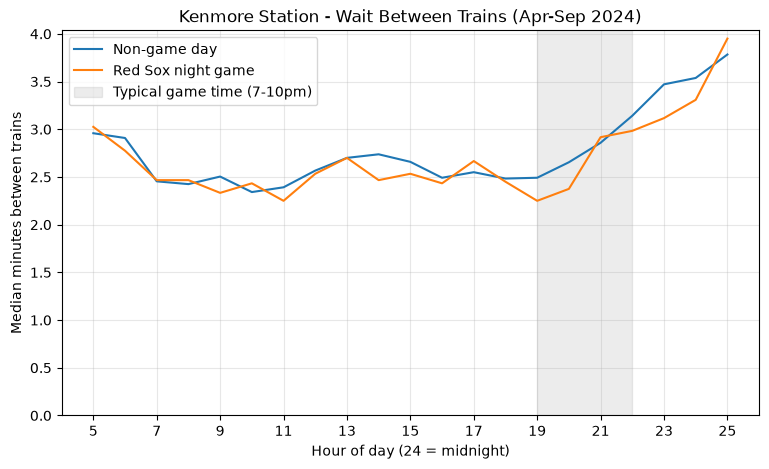

In [13]:
# night games only (first pitch 5pm or later), so crowds hit the same evening hours
games['start_hour'] = pd.to_datetime(games['start_time']).dt.hour
night_dates = games.loc[(games['team'] == 'Red Sox') & (games['start_hour'] >= 17), 'service_date']

season = hourly[(hourly['service_date'] >= '2024-04-01') & (hourly['service_date'] <= '2024-09-30')]
kenmore = season[(season['parent_station'] == 'place-kencl') & (season['hour'] >= 5) & (season['hour'] <= 25)]

weekday = kenmore[kenmore['service_date'].dt.day_of_week < 5]
night = weekday[weekday['service_date'].isin(night_dates)]
normal = weekday[~weekday['game_day']]
print('night game days:', night['service_date'].nunique())
print('non-game days:', normal['service_date'].nunique())

game_line = night.groupby('hour')['median_headway_min'].median()
normal_line = normal.groupby('hour')['median_headway_min'].median()

plt.figure(figsize=(9, 5))
plt.plot(normal_line.index, normal_line.values, label='Non-game day')
plt.plot(game_line.index, game_line.values, label='Red Sox night game')
plt.axvspan(19, 22, color='gray', alpha=0.15, label='Typical game time (7-10pm)')
plt.xlabel('Hour of day (24 = midnight)')
plt.ylabel('Median minutes between trains')
plt.title('Kenmore Station - Wait Between Trains (Apr-Sep 2024)')
plt.xticks(range(5, 26, 2))
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Kenmore: trains per hour on night game days
Checks whether the MBTA runs extra trains for games, which would explain why waits don't get longer.

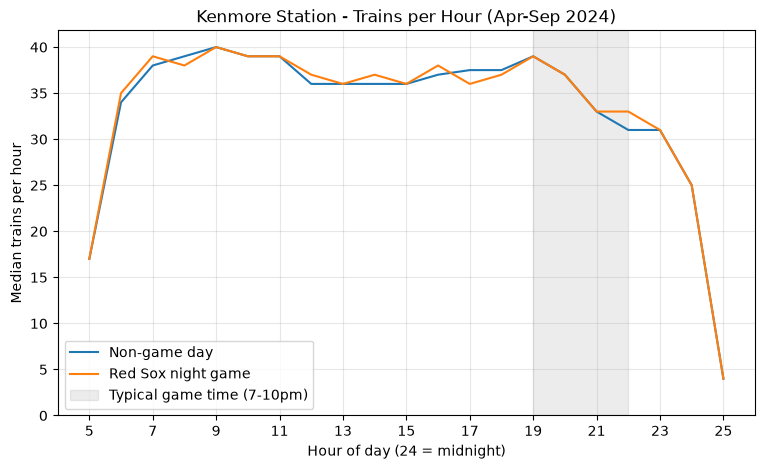

hour
5     0.0
6     1.0
7     1.0
8    -1.0
9     0.0
10    0.0
11    0.0
12    1.0
13    0.0
14    1.0
15    0.0
16    1.0
17   -1.5
18   -0.5
19    0.0
20    0.0
21    0.0
22    2.0
23    0.0
24    0.0
25    0.0
Name: n_departures, dtype: float64

In [14]:
game_trains = night.groupby('hour')['n_departures'].median()
normal_trains = normal.groupby('hour')['n_departures'].median()

plt.figure(figsize=(9, 5))
plt.plot(normal_trains.index, normal_trains.values, label='Non-game day')
plt.plot(game_trains.index, game_trains.values, label='Red Sox night game')
plt.axvspan(19, 22, color='gray', alpha=0.15, label='Typical game time (7-10pm)')
plt.xlabel('Hour of day (24 = midnight)')
plt.ylabel('Median trains per hour')
plt.title('Kenmore Station - Trains per Hour (Apr-Sep 2024)')
plt.xticks(range(5, 26, 2))
plt.ylim(bottom=0)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# extra trains per hour on game days
(game_trains - normal_trains).round(1)